In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from pathlib import Path
import logging
import random
from copy import deepcopy
import re
from sklearn.metrics import mean_squared_error

import mlflow
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import torch
import numpy as np
from dotenv import load_dotenv
from natsort import natsorted

from halcyon.Simulators.SimulationResult import SimulationResult
from halcyon.results.manipulate_results_df import (create_tidy_df_from_mlflow_runs, 
                                                   split_df_into_single_and_double_ko)

from halcyon.results import DfColumnNames

seed = 174
# for CPU
torch.manual_seed(seed)              
# for all GPUs
torch.cuda.manual_seed_all(seed)     
np.random.seed(seed) 
random.seed(seed) 

load_dotenv() 

logging.basicConfig(
    level=logging.INFO, 
    format='%(asctime)s - %(levelname)s - %(message)s',
    force=True  # Important in Jupyter to reset config
)
os.environ['MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR'] = 'False'

50 genes simulated dataset we want: `f02bf732b2ba4817b254bd5174f1549b`

In [2]:
runs_to_download = []

runs_to_download.extend(mlflow.search_runs(
    filter_string="attributes.status = 'FINISHED' and params.model_class = 'HybridModel' and tags.mlflow.parentRunId ='f02bf732b2ba4817b254bd5174f1549b'",
      experiment_ids=['6'], output_format='list'))

runs_to_download.extend(mlflow.search_runs(
    filter_string="attributes.status = 'FINISHED' and params.model_class = 'PyTorchODE' and tags.mlflow.parentRunId ='f02bf732b2ba4817b254bd5174f1549b'",
      experiment_ids=['7'], output_format='list'))

print(len(runs_to_download))

10


In [3]:
raw_predictions_df = create_tidy_df_from_mlflow_runs(runs_to_download)
raw_predictions_df.head()

2026-06-10 09:48:37,608 - INFO - Downloading artifacts for run 4ce2c0cbe5454315b45fb0277d11fd12
2026-06-10 09:48:38,706 - INFO - Downloading artifacts for run 1cd5efb3ef374f51ad9a5ced5e80d541
2026-06-10 09:48:39,803 - INFO - Downloading artifacts for run 5922b969bd6942d0bf5e7bf6901952e9
2026-06-10 09:48:40,779 - INFO - Downloading artifacts for run e6f120fab5b24d2ba199a4a7fa78ec25
2026-06-10 09:48:41,772 - INFO - Downloading artifacts for run c24b7e48838c4020830d1f4bd8cd5232
2026-06-10 09:48:42,776 - INFO - Downloading artifacts for run 8932651904e746d8a6ea3489e2e1860d
2026-06-10 09:48:43,681 - INFO - Downloading artifacts for run 309801d3775d45bda1aebdafde6925ca
2026-06-10 09:48:44,544 - INFO - Downloading artifacts for run b93313eef4d34ee1b065350b2aaf6bef
2026-06-10 09:48:45,412 - INFO - Downloading artifacts for run d109d3154485488e95c947f7d4476523
2026-06-10 09:48:46,272 - INFO - Downloading artifacts for run b571f3dd78084648b7c842dc4a84fae4


,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id
0,Node_0,0.0,0.180529,0.180529,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b
1,Node_1,0.0,0.567127,0.567127,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b
2,Node_2,0.0,0.000000,0.000000,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b
3,Node_3,0.0,0.382860,0.382860,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b
4,Node_4,0.0,0.091659,0.091659,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b


In [4]:
raw_predictions_df.shape

(549549, 7)

In [5]:
model_name_records = []
for run_id in raw_predictions_df['run_id'].unique():
    run = mlflow.get_run(run_id)
    model_name_records.append({
        'run_id': run_id,
        'model_name': run.data.tags['mlflow.runName'],
        'modelled_genes': run.data.params.get('modelled_gene_labels', None)})
model_name_df = pd.DataFrame(model_name_records)
raw_predictions_df = pd.merge(raw_predictions_df, model_name_df, on='run_id')
raw_predictions_df.head()

,gene,time,predicted_expression,ground_truth,condition,run_id,parent_run_id,model_name,modelled_genes
0,Node_0,0.0,0.180529,0.180529,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."
1,Node_1,0.0,0.567127,0.567127,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."
2,Node_2,0.0,0.000000,0.000000,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."
3,Node_3,0.0,0.382860,0.382860,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."
4,Node_4,0.0,0.091659,0.091659,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No..."


In [6]:
records = []
for run_id in raw_predictions_df['parent_run_id'].unique():
    ml_flow_download_path = mlflow.artifacts.download_artifacts(
        run_id=run_id, artifact_path="dataset"
    )
    sim_output = SimulationResult.load_from_pkl(
        Path(ml_flow_download_path) / "simulation_result.pkl"
    )
    sim_output.noiseless_for_testing = True
    long_form_simulation = sim_output.to_long_form_df()
    long_form_simulation[DfColumnNames.RUN_ID_COL] = run_id
    records.append(long_form_simulation)
long_form_simulation = pd.concat(records, ignore_index=True)

2026-06-10 09:48:53,080 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-10 09:48:53,093 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-10 09:48:53,095 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-10 09:48:53,104 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-10 09:48:53,122 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-10 09:48:53,130 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-10 09:48:53,151 - WARNING - Connection pool is full, discarding connection: mlflow.cropresilience.org. Connection pool size: 10
2026-06-10 09:48:53,155 - WARNING - Connection p

In [7]:
outcome = pd.merge(
    raw_predictions_df, 
    long_form_simulation, 
    left_on=['parent_run_id', 'gene', 'time', 'condition'], 
    right_on=['run_id', 'gene', 'time', 'condition'], 
    validate='m:1',
    suffixes=['_from_pred_df', '_from_simulation'])
outcome.head()

,gene,time,predicted_expression,ground_truth_from_pred_df,condition,run_id_from_pred_df,parent_run_id,model_name,modelled_genes,ground_truth_from_simulation,run_id_from_simulation
0,Node_0,0.0,0.180529,0.180529,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.022225,f02bf732b2ba4817b254bd5174f1549b
1,Node_1,0.0,0.567127,0.567127,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.557310,f02bf732b2ba4817b254bd5174f1549b
2,Node_2,0.0,0.000000,0.000000,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.080057,f02bf732b2ba4817b254bd5174f1549b
3,Node_3,0.0,0.382860,0.382860,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.702816,f02bf732b2ba4817b254bd5174f1549b
4,Node_4,0.0,0.091659,0.091659,KO: Node_22. Env: None,4ce2c0cbe5454315b45fb0277d11fd12,f02bf732b2ba4817b254bd5174f1549b,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.057769,f02bf732b2ba4817b254bd5174f1549b


In [8]:
outcome = outcome[['gene', 'time', 'predicted_expression', 
       'condition', 'run_id_from_pred_df', 'model_name', 'modelled_genes',
       'ground_truth_from_simulation']]

outcome = outcome.rename(columns={"run_id_from_pred_df": "run_id", "ground_truth_from_simulation": "noiseless_ground_truth"})

In [9]:
outcome['model_name'].unique()

array(['HybridModel', 'PyTorchODE'], dtype=object)

In [10]:
single_ko_df, double_ko_df = split_df_into_single_and_double_ko(outcome)

In [11]:
double_ko_df.head()

,gene,time,predicted_expression,condition,run_id,model_name,modelled_genes,noiseless_ground_truth
39900,Node_0,0.0,0.000000,"KO: Node_5, Node_13. Env: None",4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.102054
39901,Node_1,0.0,0.540319,"KO: Node_5, Node_13. Env: None",4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.520959
39902,Node_2,0.0,0.744383,"KO: Node_5, Node_13. Env: None",4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.628458
39903,Node_3,0.0,0.190828,"KO: Node_5, Node_13. Env: None",4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.398028
39904,Node_4,0.0,0.450183,"KO: Node_5, Node_13. Env: None",4ce2c0cbe5454315b45fb0277d11fd12,HybridModel,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.271006


In [12]:
def annotate_kos_in_df(paired):
    paired = deepcopy(paired)
    def make_ko_lookup(df):
        unique_combos = df[['condition', 'modelled_genes']].drop_duplicates()
    
        lookup = {}
        for _, row in unique_combos.iterrows():
            cond = row['condition']
            genes = row['modelled_genes']
            key = (cond, genes)

            kos = re.findall(r"Node_\d+", cond)
        
            if all(f"'{ko}'" in genes for ko in kos):
                ko_in_modelled_genes = 'fully'
            elif any(f"'{ko}'" in genes for ko in kos):
                ko_in_modelled_genes = 'partially'
            else:
                ko_in_modelled_genes = 'none'
        
            lookup[key] = ko_in_modelled_genes
    
        return lookup

    lookup = make_ko_lookup(paired)
    paired['ko_in_mm'] = paired.apply(
        lambda row: lookup[(
            row['condition'],
            row['modelled_genes'] if row['modelled_genes'] is not None else None
        )],
    axis=1
)
    paired['gene_in_mm'] = paired.apply(lambda row:
             bool(re.search(rf"'{row['gene']}'", row['modelled_genes'])), axis=1)
    return paired


In [13]:
groupby_list = [
    'model_name',
    'modelled_genes',
    DfColumnNames.GENE_COL,
    DfColumnNames.CONDITION_COL,
]
mse_df = (
    double_ko_df.groupby(groupby_list, dropna=False)
    .apply(
        lambda g: mean_squared_error(
            g['noiseless_ground_truth'], g['predicted_expression']
        ),
        include_groups=False,
    )
    .reset_index(name=DfColumnNames.MSE_COL)
)

mm_mse = mse_df[mse_df['model_name'] == 'PyTorchODE'][['gene', 'condition', 'MSE', 'modelled_genes']].rename(columns={'MSE': 'mm_mse'})
hybrid_mse = mse_df[mse_df['model_name'] == 'HybridModel'][['gene', 'condition', 'MSE', 'modelled_genes']].rename(columns={'MSE': 'hybrid_mse'})

paired = hybrid_mse.merge(mm_mse, on=['gene', 'condition', 'modelled_genes'])


In [14]:
paired

,gene,condition,hybrid_mse,modelled_genes,mm_mse
0,Node_1,"KO: Node_0, Node_8. Env: None",0.003077,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.005233
1,Node_1,"KO: Node_1, Node_10. Env: None",0.044812,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.006091
2,Node_1,"KO: Node_1, Node_11. Env: None",0.043474,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.001658
3,Node_1,"KO: Node_1, Node_14. Env: None",0.043834,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.001664
4,Node_1,"KO: Node_1, Node_15. Env: None",0.050728,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.006291
...,...,...,...,...,...
622,Node_40,"KO: Node_1, Node_9. Env: None",0.001749,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.001892
623,Node_41,"KO: Node_1, Node_14. Env: None",0.003617,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.001280
624,Node_41,"KO: Node_1, Node_9. Env: None",0.003330,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.001035
625,Node_9,"KO: Node_1, Node_14. Env: None",0.001690,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.000195


In [15]:
paired = annotate_kos_in_df(paired)
paired

,gene,condition,hybrid_mse,modelled_genes,mm_mse,ko_in_mm,gene_in_mm
0,Node_1,"KO: Node_0, Node_8. Env: None",0.003077,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.005233,partially,True
1,Node_1,"KO: Node_1, Node_10. Env: None",0.044812,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.006091,partially,True
2,Node_1,"KO: Node_1, Node_11. Env: None",0.043474,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.001658,fully,True
3,Node_1,"KO: Node_1, Node_14. Env: None",0.043834,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.001664,partially,True
4,Node_1,"KO: Node_1, Node_15. Env: None",0.050728,"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'No...",0.006291,fully,True
...,...,...,...,...,...,...,...
622,Node_40,"KO: Node_1, Node_9. Env: None",0.001749,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.001892,partially,True
623,Node_41,"KO: Node_1, Node_14. Env: None",0.003617,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.001280,partially,True
624,Node_41,"KO: Node_1, Node_9. Env: None",0.003330,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.001035,partially,True
625,Node_9,"KO: Node_1, Node_14. Env: None",0.001690,"['Node_9', 'Node_18', 'Node_14', 'Node_21', 'N...",0.000195,partially,True


In [22]:
import string
genes_to_letter_map = {}
i = 0
for genes in paired['modelled_genes'].unique():
    if genes is None:
        continue
    genes_to_letter_map[genes] = string.ascii_uppercase[i]
    i += 1
genes_to_letter_map

{"['Node_11', 'Node_1', 'Node_8', 'Node_31', 'Node_15', 'Node_16', 'Node_20', 'Node_38', 'Node_27', 'Node_34', 'Node_42', 'Node_44', 'Node_46']": 'A',
 "['Node_13', 'Node_0', 'Node_24', 'Node_5', 'Node_4', 'Node_28', 'Node_29', 'Node_19']": 'B',
 "['Node_2', 'Node_6', 'Node_23', 'Node_3', 'Node_12', 'Node_7', 'Node_25', 'Node_17', 'Node_35', 'Node_37', 'Node_43', 'Node_45', 'Node_47', 'Node_48']": 'C',
 "['Node_30', 'Node_39', 'Node_10', 'Node_22', 'Node_26', 'Node_32', 'Node_33', 'Node_49']": 'D',
 "['Node_9', 'Node_18', 'Node_14', 'Node_21', 'Node_36', 'Node_40', 'Node_41']": 'E'}

In [24]:
paired['subset_genes_name'] = paired['modelled_genes'].map(genes_to_letter_map).fillna('')

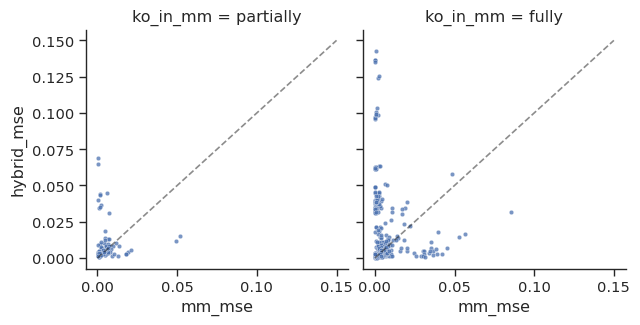

In [28]:
sns.set_theme()
sns.set_context("paper", font_scale=1.2)
sns.set_style('ticks')
palette = sns.color_palette()
g = sns.relplot(data=paired, x='mm_mse', y='hybrid_mse', col='ko_in_mm', 
                  alpha=.75, s=10, aspect=1)
g.figure.set_size_inches(6, 3) 
# g.figure.suptitle('Some title', y=1.12)
for ax in g.axes.flat:
    ax.plot([0, .15], [0, .15], 'k--', alpha=0.5)
    for collection in ax.collections:
        collection.set_rasterized(True)
# for text in g._margin_titles_texts:
#     text.set_visible(False)

g.savefig("mm_vs_hybrid.pdf", dpi=600, bbox_inches='tight')